Эпизод 1. Чтение файлов и визуализация тестовых наборов данных

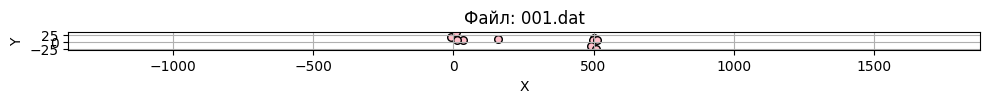

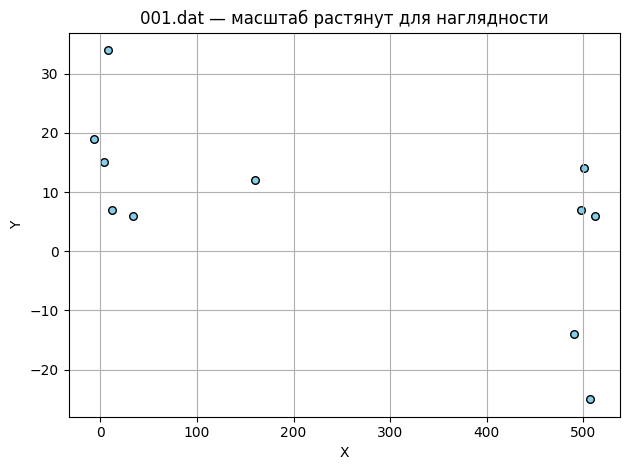

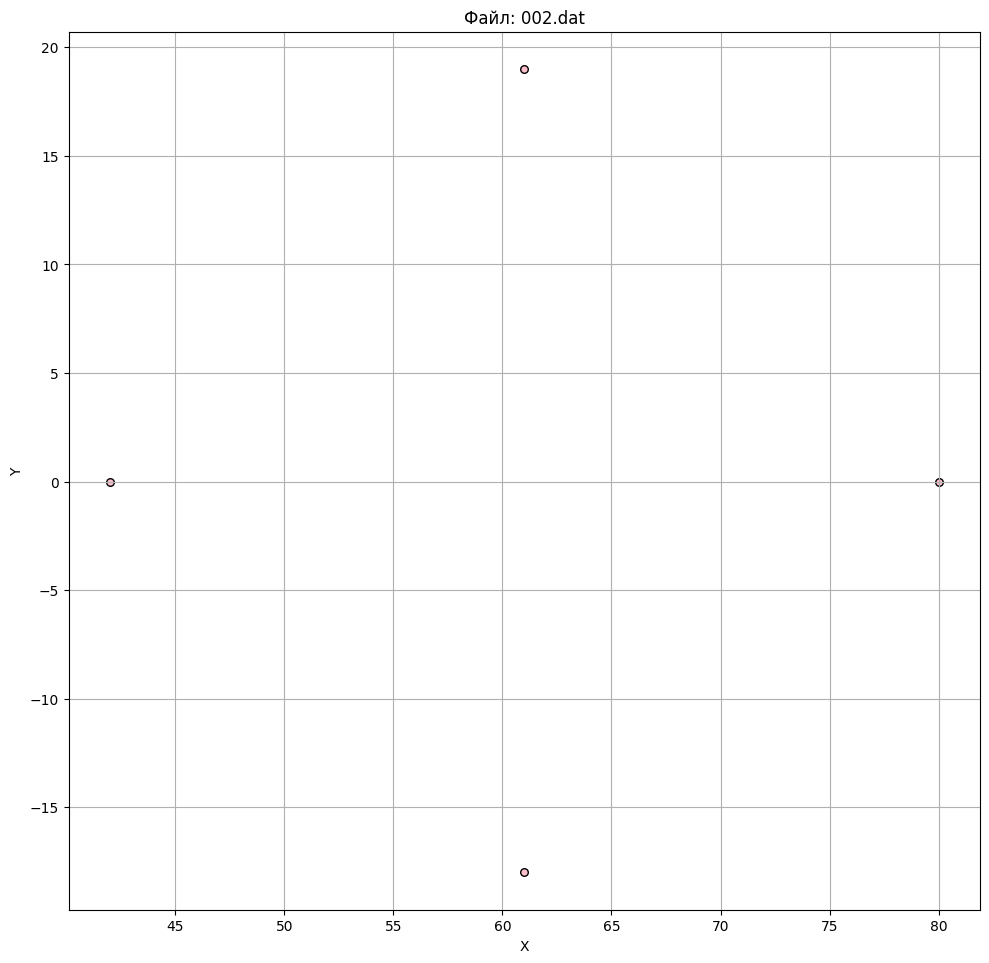

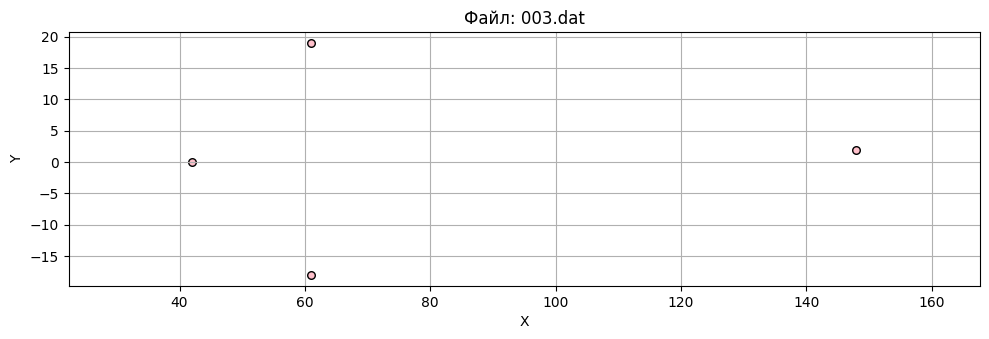

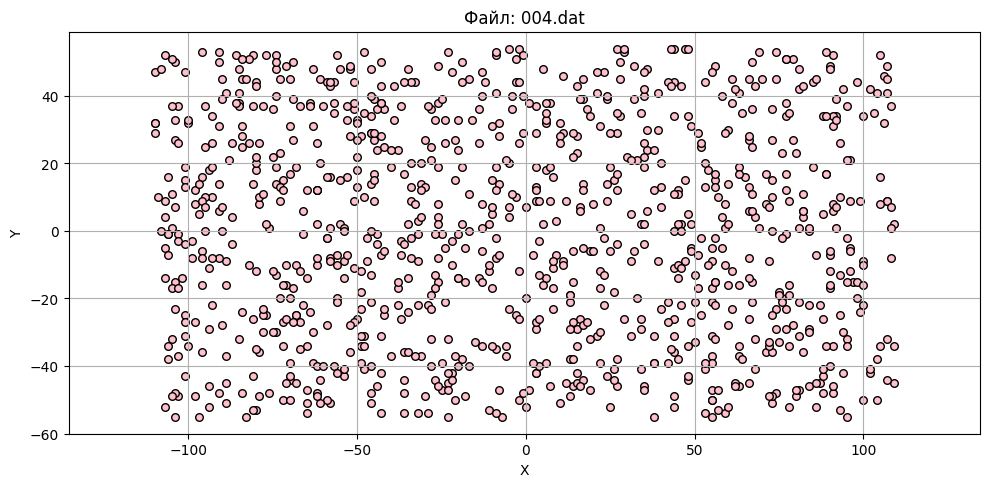

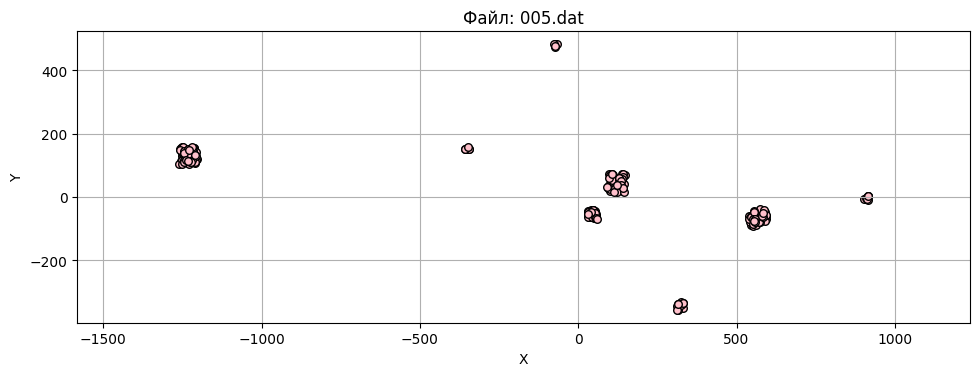

In [30]:
import matplotlib.pyplot as plt


def read_points(file):
    xp = []
    yp = []
    with open(file, 'r') as f:
        n = int(f.readline().strip())
        for _ in range(n):
            line = f.readline().strip()
            x, y = map(float, line.split())
            xp.append(x)
            yp.append(y)
    return xp, yp


files = ['001.dat', '002.dat', '003.dat', '004.dat', '005.dat']

for f_name in files:
    x, y = read_points(f_name)
    
    width = max(x) - min(x)
    height = max(y) - min(y)
    
    
    if width == 0: width = 1
    if height == 0: height = 1
    
    
    base = 10
    ratio = width / height
    
    if ratio >= 1:
        fig_w, fig_h = base, base / ratio
    else:
        fig_w, fig_h = base * ratio, base
    
    
    plt.figure(figsize=(fig_w, fig_h))
    plt.scatter(x, y, c='pink', s=30, edgecolors='black')
    plt.title(f"Файл: {f_name}")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.axis('equal')  # 1:1 масштаб
    plt.grid(True)
    plt.tight_layout()  # Убираем лишние поля
    plt.show()


    if f_name == '001.dat':
        plt.figure()
        plt.scatter(x, y, c='skyblue', s=30, edgecolors='black')
        plt.title(f"{f_name} — масштаб растянут для наглядности")
        plt.xlabel("X")
        plt.ylabel("Y")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

Эпизод2

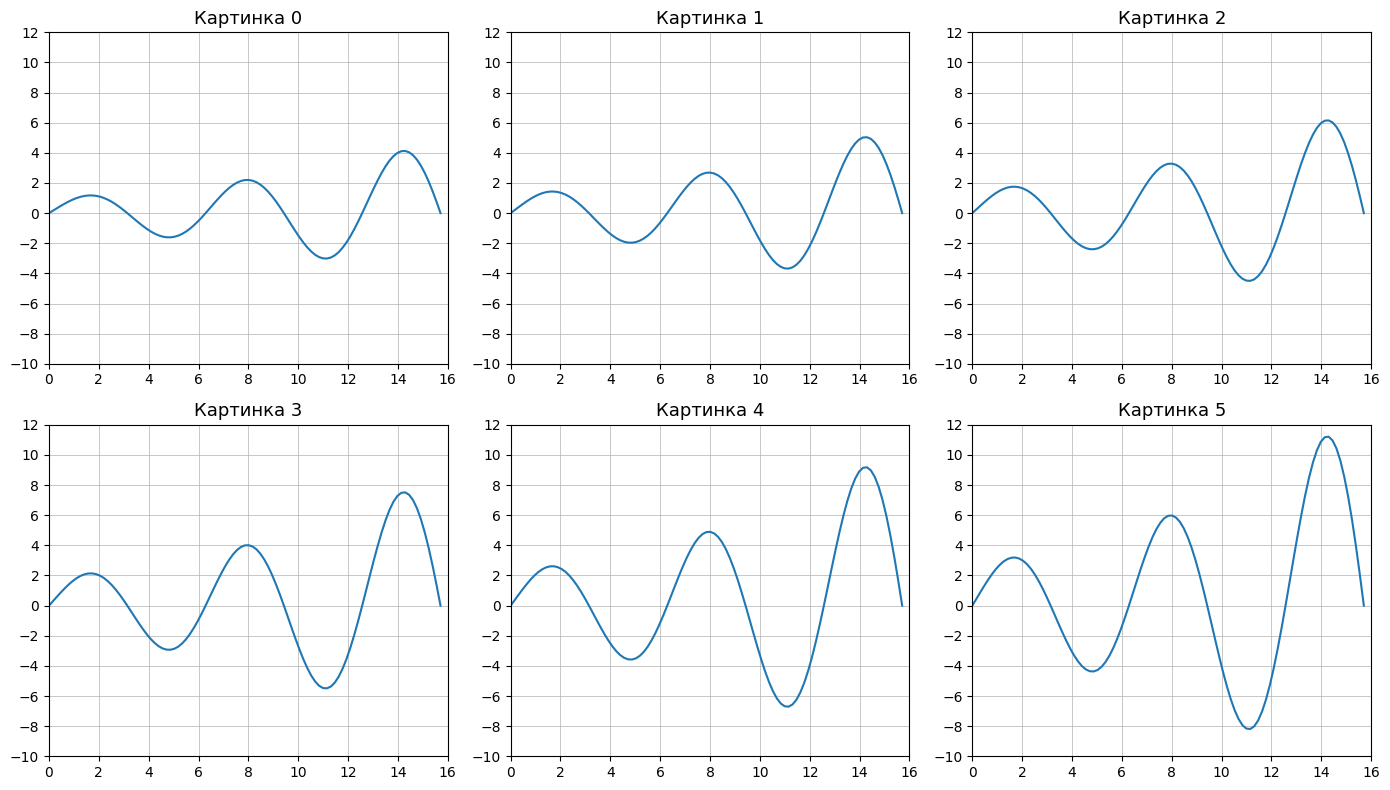

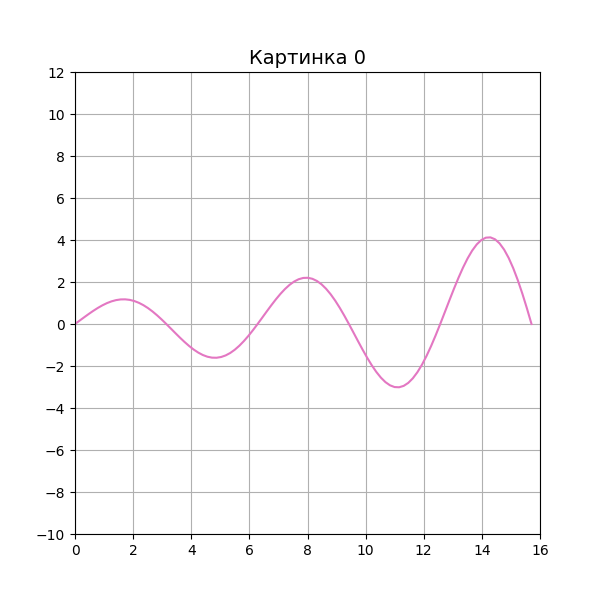

In [37]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import Image, display

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i in range(6):
    xs, ys = frames[i]
    ax = axes[i]
    ax.plot(xs, ys, color='tab:blue')
    ax.set_title(f"Картинка {i}", fontsize=13)
    ax.set_xlim(0, 16)
    ax.set_ylim(-10, 12)
    ax.set_xticks(range(0, 17, 2))
    ax.set_yticks(range(-10, 13, 2))
    ax.grid(True, which='both', linestyle='-', linewidth=0.5)

plt.tight_layout()
plt.show()

fig2, ax2 = plt.subplots(figsize=(6, 6))

def update(i):
    ax2.clear()
    xs, ys = frames[i]
    ax2.plot(xs, ys, color='tab:pink')
    ax2.set_title(f"Картинка {i}", fontsize=14)
    ax2.set_xlim(0, 16)
    ax2.set_ylim(-10, 12)
    ax2.set_xticks(range(0, 17, 2))
    ax2.set_yticks(range(-10, 13, 2))
    ax2.grid(True)

ani = animation.FuncAnimation(fig2, update, frames=len(frames), interval=500)
ani.save('process.gif', writer='pillow', fps=2)
plt.close(fig2)

display(Image(filename='process.gif'))

Эпизод3.

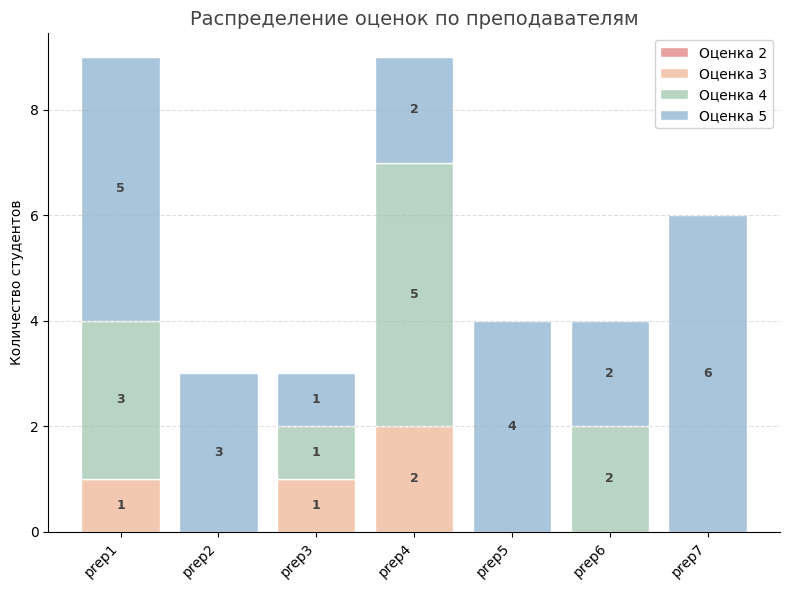

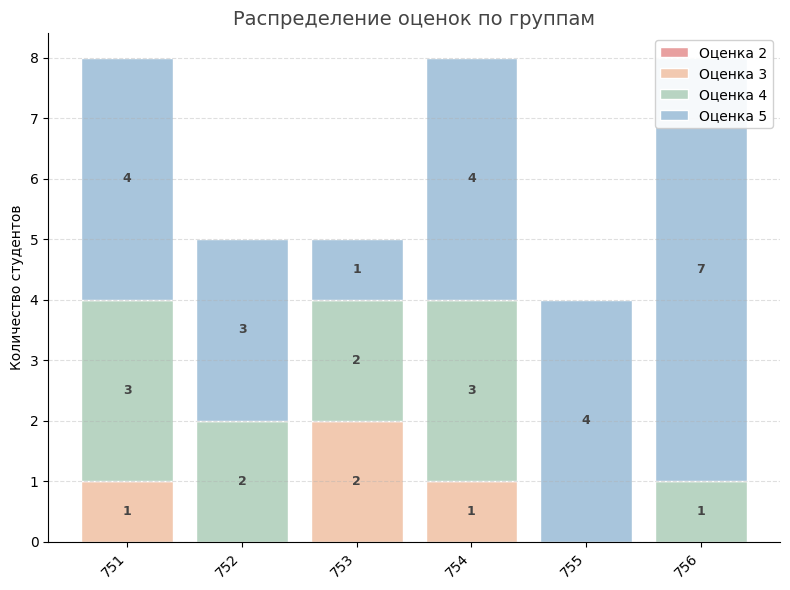

In [39]:
import matplotlib.pyplot as plt
import csv
from collections import defaultdict, Counter

teachers = defaultdict(Counter)
groups = defaultdict(Counter)

with open('students.csv', 'r', encoding='utf-8') as f:
    reader = csv.reader(f, delimiter=';')
    for row in reader:
        if len(row) < 3:
            continue
        teacher, group, grade = row[0].strip(), row[1].strip(), row[2].strip()
        teachers[teacher][grade] += 1
        groups[group][grade] += 1

grade_order = ['2', '3', '4', '5']
colors = {
    '2': '#e8a0a0',
    '3': '#f2c9b0',
    '4': '#b8d4c2',
    '5': '#a8c5dc',
}

def make_stacked_bar(data, title):
    keys = sorted(data.keys())
    fig, ax = plt.subplots(figsize=(max(8, len(keys) * 0.8), 6))
    
    x = range(len(keys))
    bottoms = [0] * len(keys)
    
    for grade in grade_order:
        values = [data[k].get(grade, 0) for k in keys]
        bars = ax.bar(x, values, bottom=bottoms, color=colors[grade],
                      label=f"Оценка {grade}", edgecolor='white', linewidth=1)
        for bar, val in zip(bars, values):
            if val > 0:
                ax.text(bar.get_x() + bar.get_width() / 2,
                        bar.get_y() + bar.get_height() / 2,
                        str(val), ha='center', va='center',
                        fontsize=9, color='#444444', fontweight='bold')
        bottoms = [b + v for b, v in zip(bottoms, values)]
    
    ax.set_xticks(list(x))
    ax.set_xticklabels(keys, rotation=45, ha='right')
    ax.set_ylabel("Количество студентов")
    ax.set_title(title, fontsize=14, color='#444444')
    ax.legend(loc='upper right', framealpha=0.9)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.show()

make_stacked_bar(teachers, "Распределение оценок по преподавателям")
make_stacked_bar(groups, "Распределение оценок по группам")